In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold,cross_val_score,GridSearchCV
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error,mean_absolute_percentage_error
from scipy.stats import ttest_rel


In [39]:
df = pd.read_csv("machine_rul.csv")

print(df.shape)
print(df.isnull().sum())
print(df.head())
print(df.info())
print(df.describe())


(1000, 20)
Record_ID                       0
Machine_Type                    8
Shift                           0
Maintenance_Status              7
Operating_Hours                 0
Temperature_C                  18
Vibration_mm_s                 16
Pressure_Bar                   14
Rotational_Speed_RPM            0
Lubrication_Level              12
Motor_Current_A                 0
Power_Consumption_kW           10
Ambient_Temperature_C           0
Load_Percentage                 0
Humidity_Percentage            10
Coolant_Temperature_C           0
Bearing_Wear_Index              0
Previous_Failure_Count          0
Maintenance_Interval_Days       0
Remaining_Useful_Life_Hours     0
dtype: int64
  Record_ID  ... Remaining_Useful_Life_Hours
0   RUL0001  ...                 1040.928112
1   RUL0002  ...                 1997.050505
2   RUL0003  ...                 2635.202920
3   RUL0004  ...                 1606.795677
4   RUL0005  ...                 4055.564500

[5 rows x 20 columns]
<cl

In [40]:
target = "Remaining_Useful_Life_Hours"

df = df.drop_duplicates().reset_index(drop=True)
x = df.drop(columns = [target,"Record_ID"])
y = df[target]

print(x.shape)
print(y.shape)

num_cols = x.select_dtypes(include=np.number).columns.tolist()
cat_cols = x.select_dtypes(exclude=np.number).columns.tolist()

print(target)
print(num_cols)
print(cat_cols)

(1000, 18)
(1000,)
Remaining_Useful_Life_Hours
['Operating_Hours', 'Temperature_C', 'Vibration_mm_s', 'Pressure_Bar', 'Rotational_Speed_RPM', 'Lubrication_Level', 'Motor_Current_A', 'Power_Consumption_kW', 'Ambient_Temperature_C', 'Load_Percentage', 'Humidity_Percentage', 'Coolant_Temperature_C', 'Bearing_Wear_Index', 'Previous_Failure_Count', 'Maintenance_Interval_Days']
['Machine_Type', 'Shift', 'Maintenance_Status']


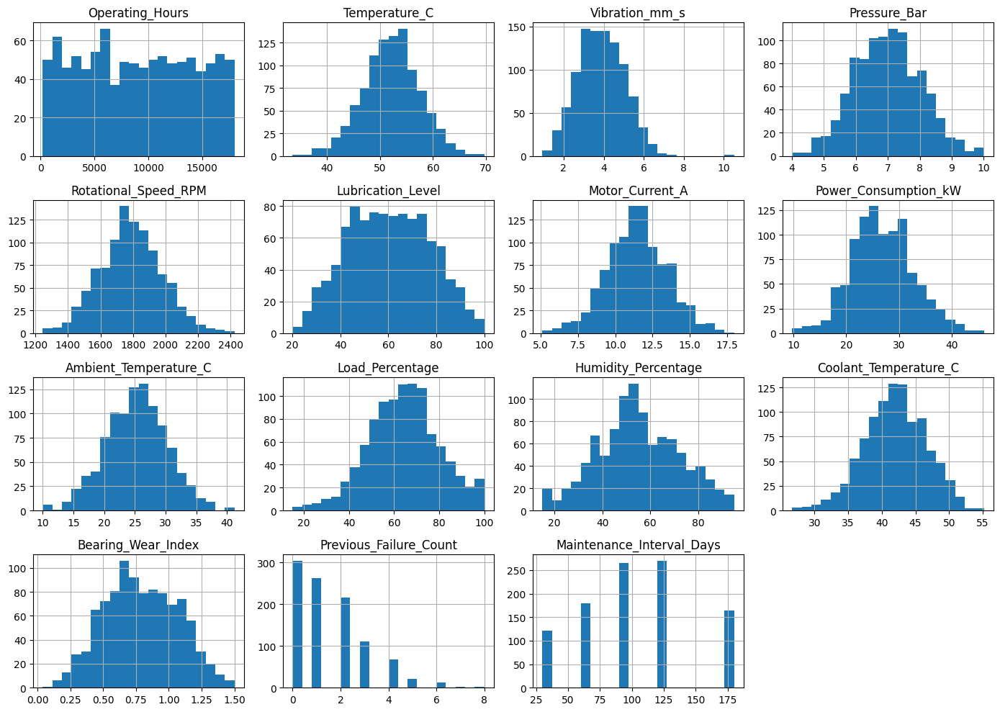

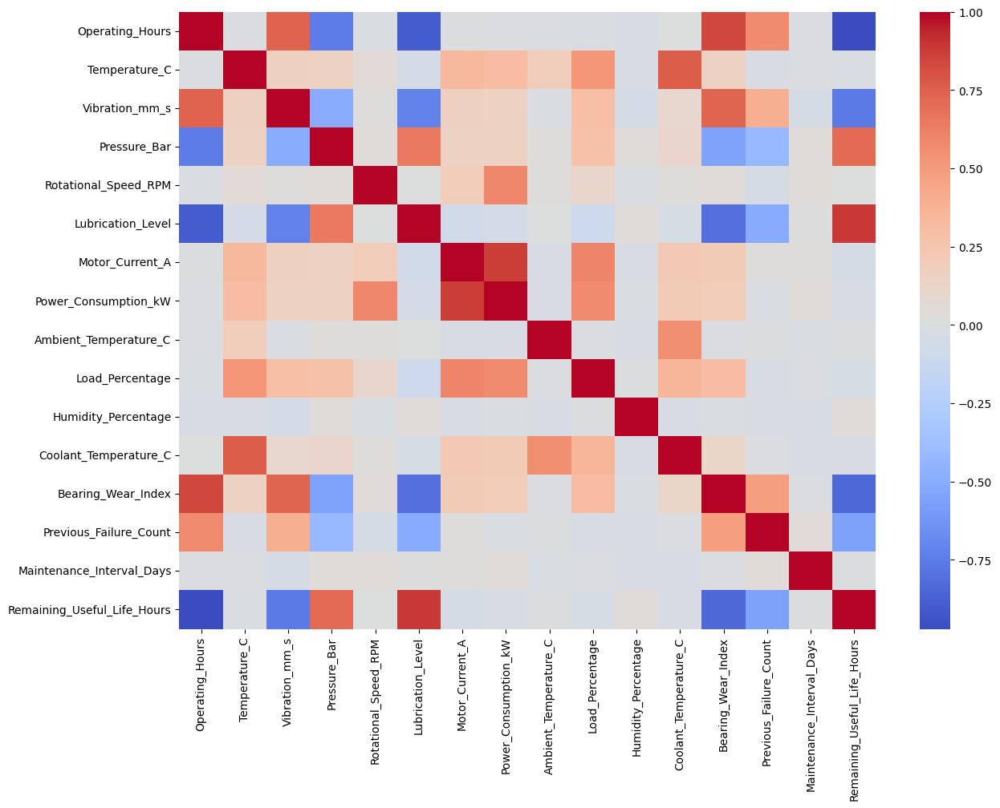

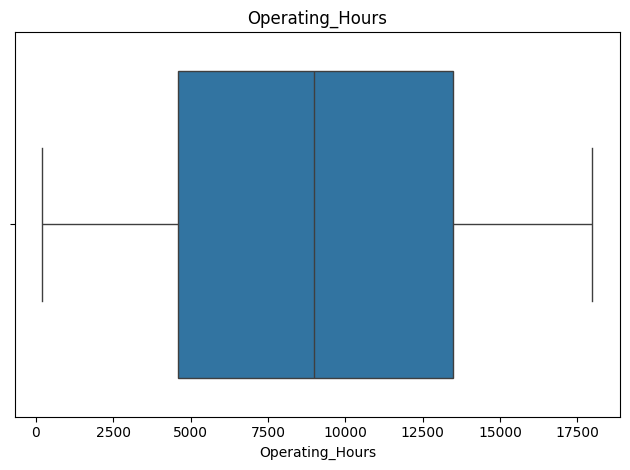

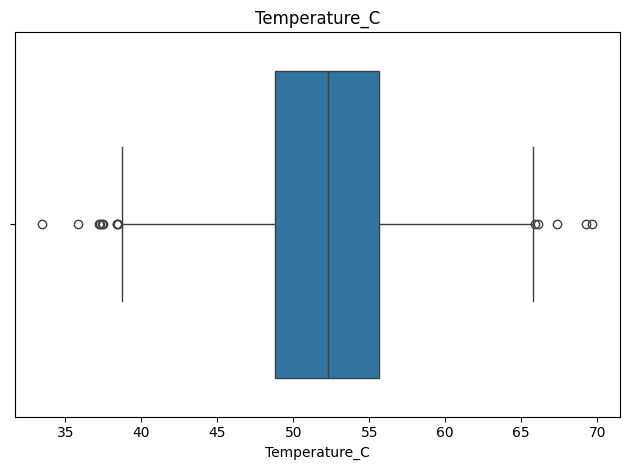

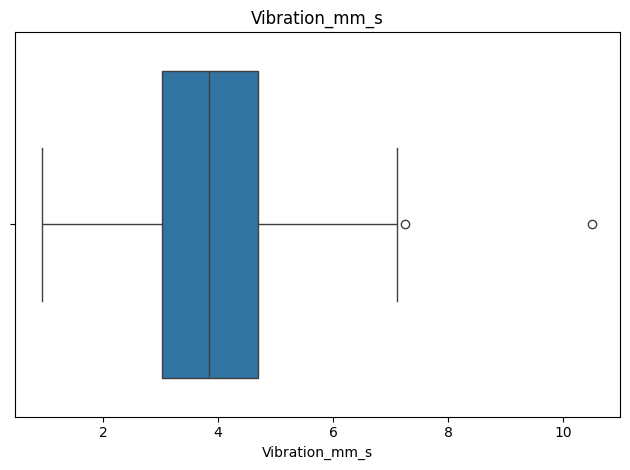

...

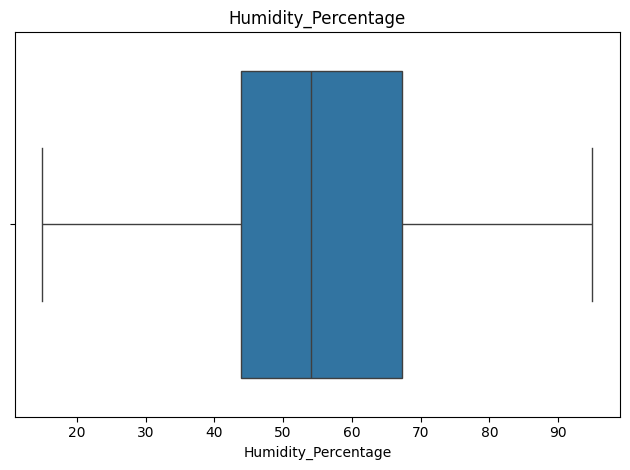

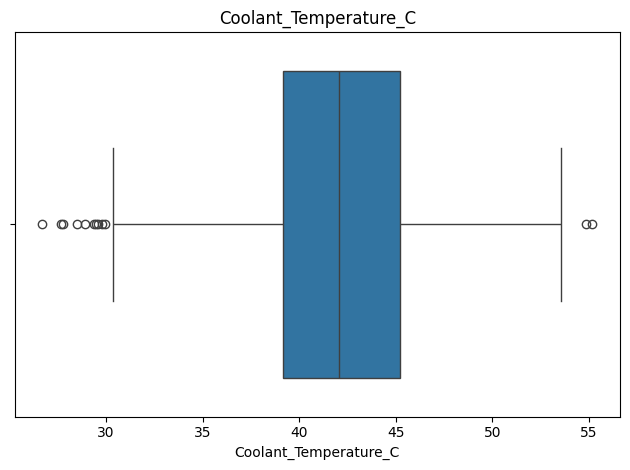

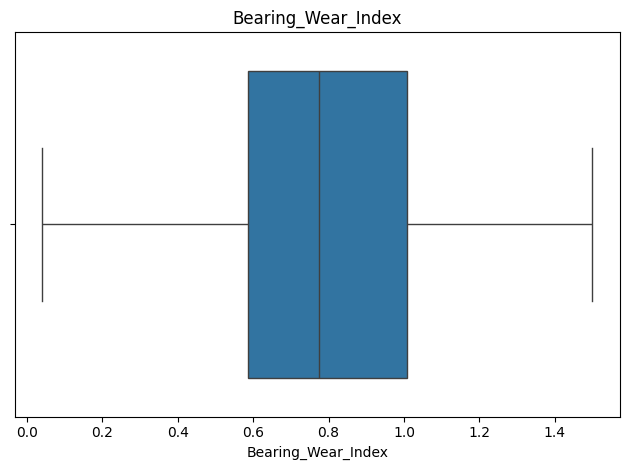

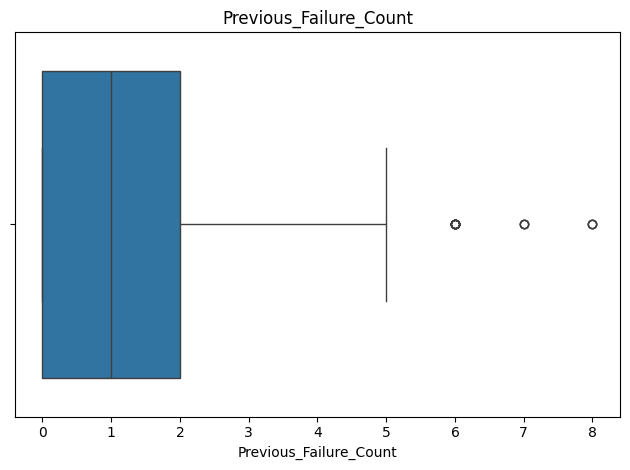

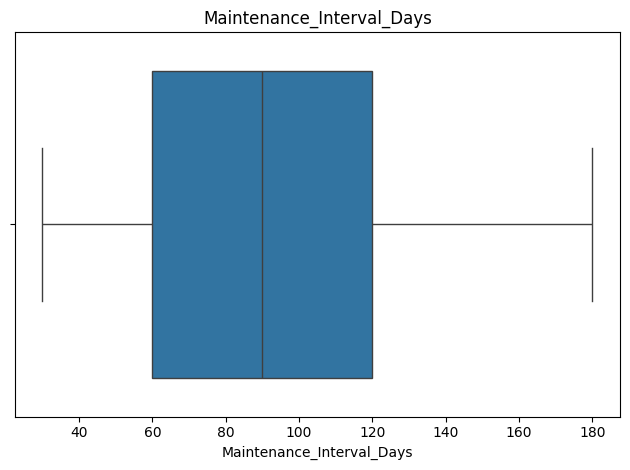

In [41]:
df[num_cols].hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 10))
sns.heatmap(df[num_cols + [target]].corr(numeric_only=True),cmap="coolwarm")
plt.show()

for col in num_cols:
  sns.boxplot(x=df[col])
  plt.title(col)
  plt.tight_layout()
  plt.show()

Preprocessing pipelines created.


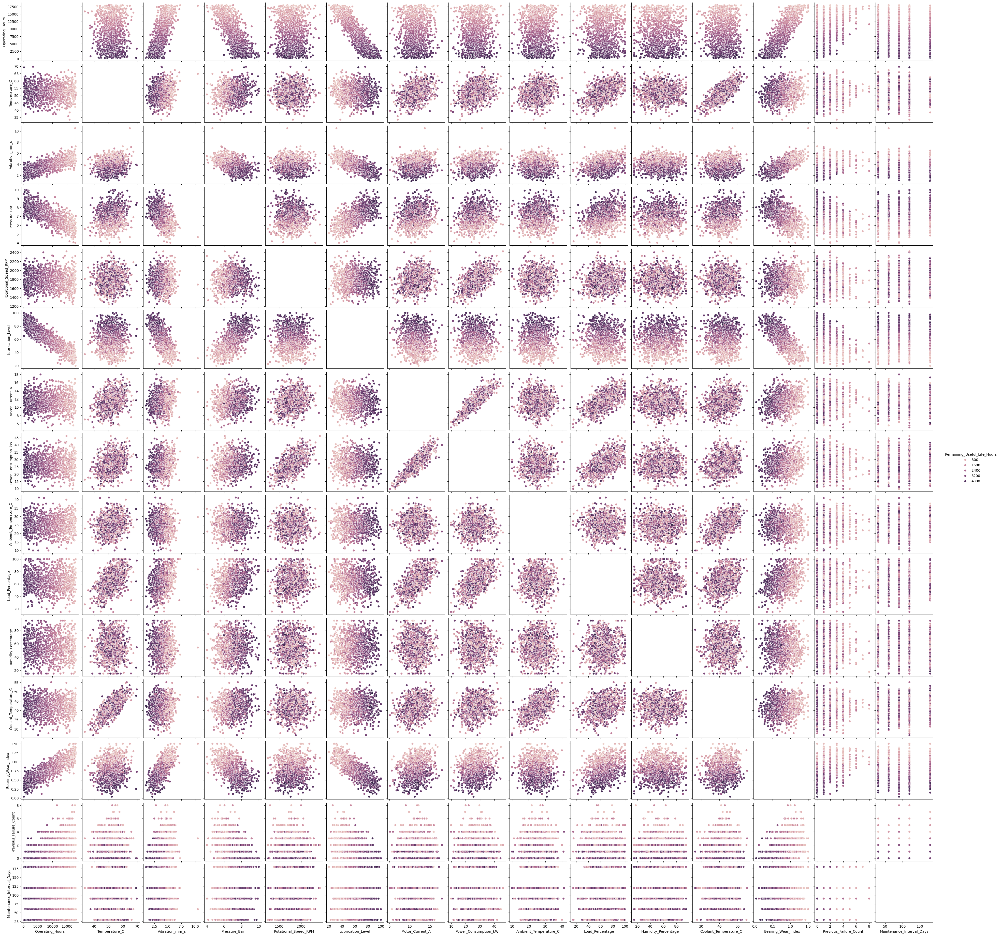

In [42]:
num_pipe = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num",num_pipe,num_cols),
    ("cat",cat_pipe,cat_cols)
])

print("Preprocessing pipelines created.")

# Corrected: use the column name string 'target' instead of the Series 'y'
sns.pairplot(df, hue=target)
plt.show()

In [43]:
model_without_pca = Pipeline([
    ("preprocessor",preprocessor),
    ("svr",SVR(kernel="rbf"))
])

param_grid = {
    "svr__C":[0.1,1,10],
    "svr__gamma":["scale","auto"],
    "svr__epsilon":[0.1,0.2,0.5]
}

cv = KFold(n_splits=5,shuffle=True,random_state=42)

grid_without_pca = GridSearchCV(
    estimator = model_without_pca,
    param_grid=param_grid,
    cv = cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_without_pca.fit(x,y)

print(grid_without_pca.best_score_ , grid_without_pca.best_params_)

-687.8283347870422 {'svr__C': 10, 'svr__epsilon': 0.5, 'svr__gamma': 'auto'}


In [44]:
model_with_pca = Pipeline([
    ("preprocessor",preprocessor),
    ("pca",PCA(n_components=0.95)),
    ("svr",SVR(kernel="rbf"))
])

param_grid = {
    "svr__C":[0.1,1,10],
    "svr__gamma":["scale","auto"],
    "svr__epsilon":[0.1,0.2,0.5]
}

cv = KFold(n_splits=5,shuffle=True,random_state=42)

grid_with_pca = GridSearchCV(
    estimator = model_with_pca,
    param_grid=param_grid,
    cv = cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_with_pca.fit(x,y)

print(grid_with_pca.best_score_ , grid_with_pca.best_params_)

-738.3283992448565 {'svr__C': 10, 'svr__epsilon': 0.5, 'svr__gamma': 'scale'}


In [45]:
best_pca_pipe = grid_with_pca.best_estimator_
preprocessor_fitted = best_pca_pipe.named_steps["preprocessor"]
x_transformed = preprocessor_fitted.transform(x)

pca_fitted = best_pca_pipe.named_steps["pca"]

print(x_transformed.shape[1],pca_fitted.n_components_,pca_fitted.explained_variance_ratio_,pca_fitted.explained_variance_ratio_.sum())


24 15 [0.25429254 0.18804195 0.1023661  0.06510677 0.06059726 0.05778827
 0.04230092 0.03734288 0.03133112 0.02250542 0.0212552  0.02054529
 0.01755618 0.01678989 0.01488037] 0.9527001671510589


In [46]:
best_no_pca = grid_without_pca.best_estimator_
preprocessor_fitted = best_no_pca.named_steps["preprocessor"]
x_transformed = preprocessor_fitted.transform(x)


print(x_transformed.shape[1],pca_fitted.n_components_,pca_fitted.explained_variance_ratio_,pca_fitted.explained_variance_ratio_.sum())


24 15 [0.25429254 0.18804195 0.1023661  0.06510677 0.06059726 0.05778827
 0.04230092 0.03734288 0.03133112 0.02250542 0.0212552  0.02054529
 0.01755618 0.01678989 0.01488037] 0.9527001671510589


In [47]:
rmse_no_pca = -cross_val_score(best_no_pca,x,y,cv=cv,scoring="neg_root_mean_squared_error")
rmse_pca = -cross_val_score(best_pca_pipe,x,y,cv=cv,scoring="neg_root_mean_squared_error")

comparison = pd.DataFrame({
    "Fold" : [1,2,3,4,5],
    "rmse without pca":rmse_no_pca,
    "rmse with pca":rmse_pca
})

comparison["diff"] = comparison["rmse without pca"] - comparison["rmse with pca"]

print(comparison)
print("\nMean RMSE without PCA:", rmse_no_pca.mean())
print("Std RMSE without PCA:", rmse_no_pca.std())
print("Mean RMSE with PCA:", rmse_pca.mean())
print("Std RMSE with PCA:", rmse_pca.std())


   Fold  rmse without pca  rmse with pca       diff
0     1        694.294727     740.064043 -45.769316
1     2        639.017105     683.906489 -44.889384
2     3        674.828049     731.184643 -56.356594
3     4        719.972334     771.781188 -51.808854
4     5        711.029458     764.705633 -53.676174

Mean RMSE without PCA: 687.8283347870422
Std RMSE without PCA: 28.861346619517807
Mean RMSE with PCA: 738.3283992448565
Std RMSE with PCA: 31.082591834348595


In [50]:
train_no_pca = -cross_val_score(best_no_pca,x,y,cv=cv,scoring="neg_root_mean_squared_error")
train_pca = -cross_val_score(best_pca_pipe,x,y,cv=cv,scoring="neg_root_mean_squared_error")

pred_no_pca = best_no_pca.predict(x)
pred_pca = best_pca_pipe.predict(x)

def print_metrics(name, actual, predicted):
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    print("\n", name)
    print("RMSE:", rmse)
    print("MAE:", mae)
    print("R2:", r2)
    print("MAPE (%):", mape)

print_metrics("Without PCA", y, pred_no_pca)
print_metrics("With PCA", y, pred_pca)


 Without PCA
RMSE: 612.0077852487096
MAE: 498.79954158790116
R2: 0.6924972946424687
MAPE (%): 44.45912200743197

 With PCA
RMSE: 670.1620318076748
MAE: 544.0877377928498
R2: 0.631281705995048
MAPE (%): 48.53770296764848


In [51]:
t_stat,p_value = ttest_rel(rmse_no_pca,rmse_pca)
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: statistically significant difference at alpha = 0.05.")
else:
    print("Do not reject H0: insufficient evidence of a significant difference at alpha = 0.05.")

T-statistic: -22.588918063065577
P-value: 2.2746603999242062e-05
Reject H0: statistically significant difference at alpha = 0.05.
